# 11 - Learning Curves (overfitting evidence for model 1 & model 2)

Retrains both models **logging train AND validation metrics every epoch**, plots
the learning curves with the early-stop point marked, and saves the figures.
This is the missing evidence to answer "is it overfitting?".

**How to read the curves**
- Train and val **close together** -> good generalisation.
- Val **flattens** while train keeps falling -> mild overfitting begins; the
  dashed line shows where **early stopping** keeps the best checkpoint.
- Val **rising sharply away** from train -> real overfitting.

Non-destructive: the retrained models are saved as `*_lc.pth` and do NOT
overwrite your deployed `model23` models. Figures are saved into `model23`.

Run top to bottom on Colab (GPU). Part A (video) is the slow one.

In [1]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. Runtime > Change runtime type > GPU, then re-run.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless seaborn gdown

GPU: NVIDIA L4
Drive ready: True


In [2]:
import os
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
PAD_TOKEN     = NUM_CLASSES
SEED          = 42

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
DATASET_ZIP = DRIVE + '/DATASET2.zip'
os.makedirs(MODELS, exist_ok=True)

NUM_FRAMES = 16; IMG = 224; BATCH = 8; LR = 1e-4
IMAGENET_MEAN = [0.485, 0.456, 0.406]; IMAGENET_STD = [0.229, 0.224, 0.225]
VIDEO_EPOCHS_CAP = 15
VIDEO_PATIENCE   = 4

SEQ_LEN = 4
SHUTTLESET_DIR = '/content/ShuttleSet22'
SEQ_EPOCHS_CAP = 40
SEQ_PATIENCE   = 8
SHUTTLE_MAP = {
    '發短球': 0, '發長球': 0,
    '挑球': 1, '防守回挑': 1,
    '長球': 2, '平球': 2, '小平球': 2, '後場抽平球': 2, '防守回抽': 2,
    '切球': 3, '過度切球': 3, '過渡切球': 3, '放小球': 3, '擋小球': 3, '勾球': 3, '推球': 3,
    '殺球': 4, '點扣': 4, '撲球': 4,
}
print('config ready | video cap', VIDEO_EPOCHS_CAP, '| seq cap', SEQ_EPOCHS_CAP)
print('mapped shot types:', len(SHUTTLE_MAP))

config ready | video cap 15 | seq cap 40
mapped shot types: 19


## Part A - Video stroke classifier (model 1) learning curve

In [3]:
import glob, zipfile, shutil
EXTRACT_DIR    = '/content/data'
GDRIVE_FILE_ID = ''

def has_all(d):
    return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS):
            return c
    return None

root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = []
    for pat in (DATASET_ZIP, DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip', '/content/*.zip'):
        zips += glob.glob(pat)
    zips = sorted(set(z for z in zips if os.path.exists(z)), key=lambda z: (0 if 'dataset' in z.lower() else 1, len(z)))
    if not zips:
        try:
            import gdown
            out = '/content/DATASET2.zip'
            if not os.path.exists(out):
                print('Downloading DATASET2.zip by file ID...')
                gdown.download(id=GDRIVE_FILE_ID, output=out, quiet=False)
            if os.path.exists(out) and os.path.getsize(out) > 1000000:
                zips = [out]
        except Exception as e:
            print('gdown failed:', e)
    if zips:
        print('Extracting', zips[0])
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z:
            z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)

DATASET_DIR = root or EXTRACT_DIR
print('Using DATASET_DIR =', DATASET_DIR)

Using DATASET_DIR = /content/data


In [4]:
import numpy as np, pandas as pd, cv2
import torch.nn as nn, torch.optim as optim
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def load_video_frames(path, num_frames=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0: cap.release(); raise ValueError('0 frames ' + path)
    idxs = np.linspace(0, total - 1, num_frames, dtype=int); frames = []
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        if ok: frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames: frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < num_frames:
        frames.append(frames[-1].copy() if frames else np.zeros((IMG, IMG, 3), np.uint8))
    return frames[:num_frames]

def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = min(size / h, size / w); nh, nw = int(h * s), int(w * s)
    r = cv2.resize(img, (nw, nh)); canvas = np.zeros((size, size, 3), np.uint8)
    y, x = (size - nh) // 2, (size - nw) // 2; canvas[y:y+nh, x:x+nw] = r; return canvas

_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def preprocess_frames(frames, size=IMG):
    out = []
    for fr in frames:
        fr = letterbox(fr, size).astype(np.float32) / 255.0
        out.append(_norm(torch.from_numpy(fr).permute(2, 0, 1)))
    return torch.stack(out)

class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try: return preprocess_frames(load_video_frames(row.file_path)), int(row.label_id)
        except Exception as e:
            print('skip', row.file_path, e); return torch.zeros(NUM_FRAMES, 3, IMG, IMG), int(row.label_id)

def build_index(root):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(root, folder)
        if not os.path.isdir(p): print('missing folder', p); continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'label_name': folder, 'group_id': gid})
    return pd.DataFrame(rows)

def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtr, dtmp = df.iloc[tr].reset_index(drop=True), df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    return dtr, dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)

class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        base = models.resnet18(weights=w)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b * t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)

def class_weights(dtr):
    cnt = dtr.label_id.value_counts().sort_index(); tot = len(dtr)
    return torch.tensor([tot / (NUM_CLASSES * cnt.get(i, 1)) for i in range(NUM_CLASSES)], dtype=torch.float32)

def run_epoch(model, loader, crit, opt=None):
    train = opt is not None
    model.train() if train else model.eval()
    tot, P, L = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if train: opt.zero_grad()
            out = model(x); loss = crit(out, y)
            if train: loss.backward(); opt.step()
            tot += loss.item() * x.size(0)
            P += out.argmax(1).cpu().tolist(); L += y.cpu().tolist()
    return tot / len(loader.dataset), accuracy_score(L, P), f1_score(L, P, average='macro'), P, L

print('video defs ready')

video defs ready


train 2828 val 658 test 732
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 243MB/s]


skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4
epoch  1  train_loss 0.832 val_loss 0.522 | train_f1 0.655 val_f1 0.796 *best
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4
epoch  2  train_loss 0.443 val_loss 0.378 | train_f1 0.836 val_f1 0.886 *best
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4
epoch  3  train_loss 0.316 val_loss 0.392 | train_f1 0.888 val_f1 0.881
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A

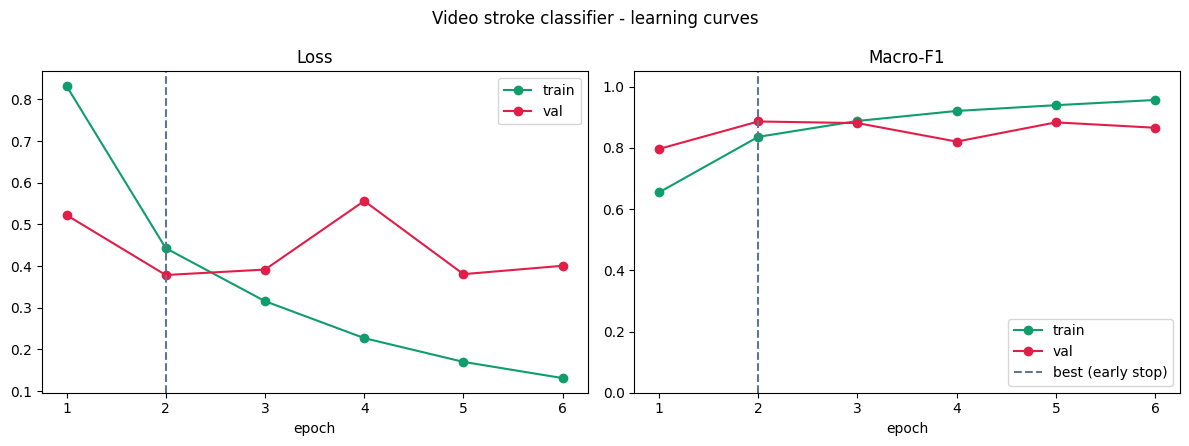

TEST acc 0.928 macro-F1 0.925  | train_f1 at best 0.836  (gap -0.089)
Saved curve -> /content/drive/MyDrive/BadmintonFYP/model23/video_learning_curve.png  |  model -> /content/drive/MyDrive/BadmintonFYP/model23/video_model_lc.pth


In [5]:
import matplotlib.pyplot as plt

df = build_index(DATASET_DIR)
assert len(df) > 0, 'No clips found - check DATASET_DIR.'
df_train, df_val, df_test = group_split(df)
print('train', len(df_train), 'val', len(df_val), 'test', len(df_test))

train_loader = DataLoader(VideoClipDataset(df_train), batch_size=BATCH, shuffle=True, num_workers=2)
val_loader   = DataLoader(VideoClipDataset(df_val),   batch_size=BATCH, num_workers=2)
test_loader  = DataLoader(VideoClipDataset(df_test),  batch_size=BATCH, num_workers=2)

model = TemporalPoolingResNet(pretrained=True).to(DEVICE)
crit = nn.CrossEntropyLoss(weight=class_weights(df_train).to(DEVICE))
opt = optim.Adam(model.parameters(), lr=LR)

CKPT_LC = MODELS + '/video_model_lc.pth'
hist = {'tr_loss': [], 'va_loss': [], 'tr_f1': [], 'va_f1': []}
best_f1, bad, best_ep = 0.0, 0, 0
for ep in range(VIDEO_EPOCHS_CAP):
    tl, ta, tf, _, _ = run_epoch(model, train_loader, crit, opt)
    vl, va, vf, _, _ = run_epoch(model, val_loader, crit)
    hist['tr_loss'].append(tl); hist['va_loss'].append(vl)
    hist['tr_f1'].append(tf);   hist['va_f1'].append(vf)
    flag = ''
    if vf > best_f1:
        best_f1, bad, best_ep = vf, 0, ep + 1
        torch.save(model.state_dict(), CKPT_LC); flag = ' *best'
    else:
        bad += 1
    print('epoch %2d  train_loss %.3f val_loss %.3f | train_f1 %.3f val_f1 %.3f%s' % (ep+1, tl, vl, tf, vf, flag))
    if bad >= VIDEO_PATIENCE:
        print('early stop at epoch', ep + 1); break
print('best val macro-F1 %.3f at epoch %d' % (best_f1, best_ep))

ex = range(1, len(hist['tr_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(ex, hist['tr_loss'], '-o', color='#0f9d6b', label='train')
ax[0].plot(ex, hist['va_loss'], '-o', color='#e11d48', label='val')
ax[0].axvline(best_ep, ls='--', color='#64748b'); ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(ex, hist['tr_f1'], '-o', color='#0f9d6b', label='train')
ax[1].plot(ex, hist['va_f1'], '-o', color='#e11d48', label='val')
ax[1].axvline(best_ep, ls='--', color='#64748b', label='best (early stop)')
ax[1].set_title('Macro-F1'); ax[1].set_xlabel('epoch'); ax[1].set_ylim(0, 1.05); ax[1].legend()
fig.suptitle('Video stroke classifier - learning curves'); plt.tight_layout()
plt.savefig(MODELS + '/video_learning_curve.png', dpi=150); plt.show()

model.load_state_dict(torch.load(CKPT_LC, map_location=DEVICE))
_, te_acc, te_f1, _, _ = run_epoch(model, test_loader, crit)
print('TEST acc %.3f macro-F1 %.3f  | train_f1 at best %.3f  (gap %.3f)' % (te_acc, te_f1, hist['tr_f1'][best_ep-1], hist['tr_f1'][best_ep-1] - te_f1))
print('Saved curve -> ' + MODELS + '/video_learning_curve.png  |  model -> ' + CKPT_LC)

## Part B - Next-shot GRU (model 2) learning curve

In [6]:
import urllib.request
from collections import Counter

SET_FOLDER = SHUTTLESET_DIR + '/set'
if not (os.path.isdir(SET_FOLDER) and os.listdir(SET_FOLDER)):
    url = 'https://github.com/wywyWang/CoachAI-Projects/archive/refs/heads/main.zip'
    zp = '/content/coachai.zip'
    print('Downloading ShuttleSet22 ...')
    urllib.request.urlretrieve(url, zp)
    with zipfile.ZipFile(zp) as z: z.extractall('/content/_ca')
    src = '/content/_ca/CoachAI-Projects-main/CoachAI-Challenge-IJCAI2023/ShuttleSet22'
    if os.path.exists(SHUTTLESET_DIR): shutil.rmtree(SHUTTLESET_DIR)
    shutil.move(src, SHUTTLESET_DIR)
print('set folder present:', os.path.isdir(SET_FOLDER))

def parse_rallies(set_folder):
    rallies, skipped = [], []
    for match in os.listdir(set_folder):
        mp = os.path.join(set_folder, match)
        if not os.path.isdir(mp): continue
        for sf in ('set1.csv', 'set2.csv', 'set3.csv'):
            path = os.path.join(mp, sf)
            if not os.path.exists(path): continue
            try: d = pd.read_csv(path)
            except Exception as e: print('read err', e); continue
            if 'rally' not in d.columns or 'type' not in d.columns: continue
            for rid, rd in d.groupby('rally'):
                shots = []
                for t in rd['type'].astype(str).str.strip():
                    if t in SHUTTLE_MAP: shots.append(SHUTTLE_MAP[t])
                    else: skipped.append(t)
                if len(shots) >= 2: rallies.append({'match_id': match, 'shots': shots})
    return rallies

def build_windows(rallies, seq_len=SEQ_LEN):
    w = []
    for r in rallies:
        s = r['shots']
        for i in range(len(s)):
            hist = s[max(0, i - seq_len):i]
            if len(hist) < seq_len: hist = [PAD_TOKEN] * (seq_len - len(hist)) + hist
            w.append({'input': hist, 'target': s[i], 'match_id': r['match_id']})
    return w

def seq_group_split(windows, val=0.15, test=0.15, seed=SEED):
    df = pd.DataFrame(windows)
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.match_id))
    dtr, dtmp = df.iloc[tr].reset_index(drop=True), df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.match_id))
    return dtr, dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)

class SequenceDataset(Dataset):
    def __init__(self, df):
        self.x = [torch.tensor(a, dtype=torch.long) for a in df['input']]
        self.y = torch.tensor(df['target'].values, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]

def seq_class_weights(dtr):
    cnt = dtr['target'].value_counts().sort_index(); tot = len(dtr)
    return torch.tensor([tot / (NUM_CLASSES * cnt.get(i, 1)) for i in range(NUM_CLASSES)], dtype=torch.float32)

class ShotPredictorGRU(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, embed=32, hidden=128, layers=2, drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(num_classes + 1, embed, padding_idx=PAD_TOKEN)
        self.gru = nn.GRU(embed, hidden, layers, batch_first=True, dropout=drop if layers > 1 else 0)
        self.fc = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden, num_classes))
    def forward(self, x):
        x = self.emb(x); o, _ = self.gru(x); return self.fc(o[:, -1, :])

def run_epoch_seq(m, loader, crit, opt=None):
    train = opt is not None
    m.train() if train else m.eval()
    tot, P, L, t3, n = 0.0, [], [], 0.0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if train: opt.zero_grad()
            lg = m(x); loss = crit(lg, y)
            if train: loss.backward(); opt.step()
            tot += loss.item() * x.size(0)
            lc = lg.detach().cpu()
            P += lc.argmax(1).tolist(); L += y.cpu().tolist()
            t3 += (lc.topk(3, 1).indices == y.cpu().unsqueeze(1)).any(1).float().sum().item(); n += len(y)
    return tot / len(loader.dataset), accuracy_score(L, P), f1_score(L, P, average='macro'), t3 / n, P, L

rallies = parse_rallies(SET_FOLDER)
windows = build_windows(rallies)
sdf_train, sdf_val, sdf_test = seq_group_split(windows)
print('rallies', len(rallies), '| windows', len(windows))
print('train', len(sdf_train), 'val', len(sdf_val), 'test', len(sdf_test))

set folder present: True
rallies 4743 | windows 51173
train 34558 val 8052 test 8563


epoch  1  train_loss 0.975 val_loss 0.961 | train_f1 0.508 val_f1 0.509 top3 0.965 *best
epoch  2  train_loss 0.932 val_loss 0.957 | train_f1 0.528 val_f1 0.521 top3 0.965 *best
epoch  3  train_loss 0.927 val_loss 0.961 | train_f1 0.529 val_f1 0.523 top3 0.966 *best
epoch  4  train_loss 0.924 val_loss 0.954 | train_f1 0.530 val_f1 0.503 top3 0.965
epoch  5  train_loss 0.925 val_loss 0.961 | train_f1 0.529 val_f1 0.524 top3 0.965 *best
epoch  6  train_loss 0.922 val_loss 0.955 | train_f1 0.532 val_f1 0.510 top3 0.966
epoch  7  train_loss 0.922 val_loss 0.957 | train_f1 0.533 val_f1 0.508 top3 0.965
epoch  8  train_loss 0.920 val_loss 0.954 | train_f1 0.534 val_f1 0.518 top3 0.965
epoch  9  train_loss 0.920 val_loss 0.958 | train_f1 0.532 val_f1 0.484 top3 0.965
epoch 10  train_loss 0.918 val_loss 0.959 | train_f1 0.534 val_f1 0.500 top3 0.966
epoch 11  train_loss 0.918 val_loss 0.964 | train_f1 0.535 val_f1 0.500 top3 0.964
epoch 12  train_loss 0.918 val_loss 0.957 | train_f1 0.534 val_

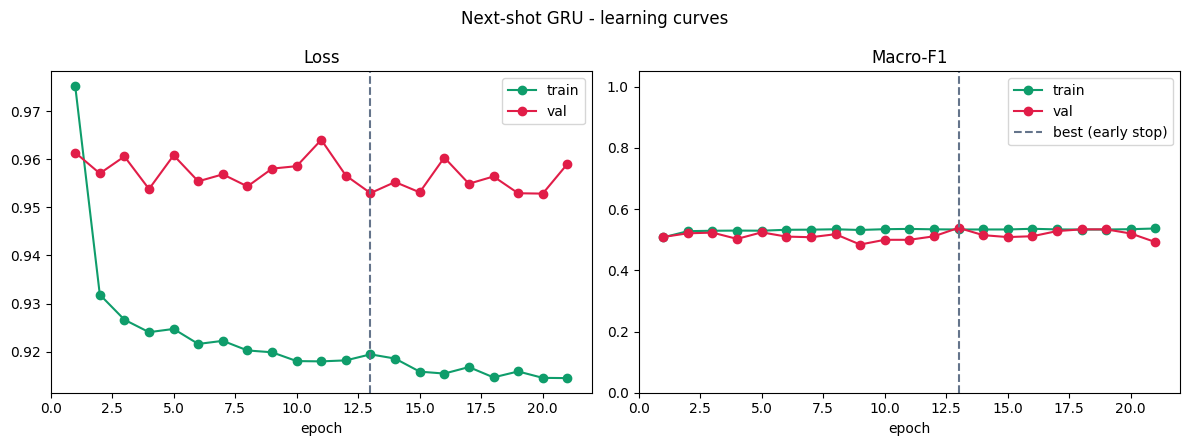

TEST acc 0.538 macro-F1 0.569 top-3 0.971
Saved curve -> /content/drive/MyDrive/BadmintonFYP/model23/sequence_learning_curve.png  |  model -> /content/drive/MyDrive/BadmintonFYP/model23/sequence_model_lc.pth


In [7]:
strain = DataLoader(SequenceDataset(sdf_train), batch_size=64, shuffle=True)
sval   = DataLoader(SequenceDataset(sdf_val),   batch_size=64)
stest  = DataLoader(SequenceDataset(sdf_test),  batch_size=64)

smodel = ShotPredictorGRU().to(DEVICE)
scrit = nn.CrossEntropyLoss(weight=seq_class_weights(sdf_train).to(DEVICE))
sopt = optim.Adam(smodel.parameters(), lr=1e-3)

SCKPT_LC = MODELS + '/sequence_model_lc.pth'
shist = {'tr_loss': [], 'va_loss': [], 'tr_f1': [], 'va_f1': []}
sbest, sbad, sbest_ep = 0.0, 0, 0
for ep in range(SEQ_EPOCHS_CAP):
    tl, ta, tf, tt3, _, _ = run_epoch_seq(smodel, strain, scrit, sopt)
    vl, va, vf, vt3, _, _ = run_epoch_seq(smodel, sval, scrit)
    shist['tr_loss'].append(tl); shist['va_loss'].append(vl)
    shist['tr_f1'].append(tf);   shist['va_f1'].append(vf)
    flag = ''
    if vf > sbest:
        sbest, sbad, sbest_ep = vf, 0, ep + 1
        torch.save(smodel.state_dict(), SCKPT_LC); flag = ' *best'
    else:
        sbad += 1
    print('epoch %2d  train_loss %.3f val_loss %.3f | train_f1 %.3f val_f1 %.3f top3 %.3f%s' % (ep+1, tl, vl, tf, vf, vt3, flag))
    if sbad >= SEQ_PATIENCE:
        print('early stop at epoch', ep + 1); break
print('best val macro-F1 %.3f at epoch %d' % (sbest, sbest_ep))

ex = range(1, len(shist['tr_loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(ex, shist['tr_loss'], '-o', color='#0f9d6b', label='train')
ax[0].plot(ex, shist['va_loss'], '-o', color='#e11d48', label='val')
ax[0].axvline(sbest_ep, ls='--', color='#64748b'); ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(ex, shist['tr_f1'], '-o', color='#0f9d6b', label='train')
ax[1].plot(ex, shist['va_f1'], '-o', color='#e11d48', label='val')
ax[1].axvline(sbest_ep, ls='--', color='#64748b', label='best (early stop)')
ax[1].set_title('Macro-F1'); ax[1].set_xlabel('epoch'); ax[1].set_ylim(0, 1.05); ax[1].legend()
fig.suptitle('Next-shot GRU - learning curves'); plt.tight_layout()
plt.savefig(MODELS + '/sequence_learning_curve.png', dpi=150); plt.show()

smodel.load_state_dict(torch.load(SCKPT_LC, map_location=DEVICE))
_, se_acc, se_f1, se_t3, _, _ = run_epoch_seq(smodel, stest, scrit)
print('TEST acc %.3f macro-F1 %.3f top-3 %.3f' % (se_acc, se_f1, se_t3))
print('Saved curve -> ' + MODELS + '/sequence_learning_curve.png  |  model -> ' + SCKPT_LC)